In [1]:
import catkit2
from catkit2 import TestbedProxy
import hcipy
from hcipy import *
from astropy.io import fits

In [2]:
testbed = TestbedProxy("localhost",5465)

In [3]:
boston_rows = 32
boston_cols = 32
boston_grid = [boston_rows, boston_cols]

alpao_rows = 11
alpao_cols = 11
alpao_grid = [alpao_rows, alpao_cols]

flat_boston = np.zeros(boston_grid)
flat_alpao = np.zeros(alpao_grid)

testbed.boston_dm.apply_shape('poke',flat_boston)
testbed.boston_dm.apply_shape('aberration',flat_boston)
testbed.boston_dm.apply_shape('correction',flat_boston)

testbed.alpao_dm.apply_shape('correction',flat_alpao)
testbed.alpao_dm.apply_shape('poke',flat_alpao)

In [4]:
def gradient_y(array_len, start, end):
    values = (end-start)/array_len
    x = np.linspace(start,end,array_len)
    y = values * x
    
    act = np.zeros((array_len, array_len))
    
    for i in range(array_len):
        act[i,:] = y[i]
        
    return(act)

In [5]:
def gradient_x(array_len, start, end):
    values = (end-start)/array_len
    x = np.linspace(start,end,array_len)
    y = values * x
    
    act = np.zeros((array_len, array_len))
    
    for i in range(array_len):
        act[:,i] = y[i]
        
    return(act)

In [6]:
flat_tilt = -gradient_y(11,-33,33)-gradient_x(11,-12,12)
testbed.alpao_dm.apply_shape('correction', flat_tilt)

In [7]:
import scipy.optimize
import hcipy
import time

num_modes = 2 + 3 + 4 + 5 + 6 + 7 + 8 + 9 + 10
actuator_grid = hcipy.make_pupil_grid(11, 1)
zernike_modes = hcipy.make_zernike_basis(num_modes, 1, actuator_grid, 2)

k = 17

start_time=time.time()
print(start_time)

def f(x):
    testbed.alpao_dm.apply_shape('poke', zernike_modes.linear_combination(x).shaped)
    
    img = np.sum(list(testbed.pywfs_camera.take_raw_exposures(2)), axis=0) / 2
    img = np.roll(img, (0, -5), axis=(1, 0))[k:-k, k:-k]
    n = img.shape[0]
                  
    a = img[:n // 2, :n // 2]
    b = img[n // 2:, :n // 2]
    c = img[:n // 2, n // 2:]
    d = img[n // 2:, n // 2:]
    
    grad_x = a - b + c - d
    grad_y = a + b - c - d
    
    res = (np.abs(grad_x)**2 + np.abs(grad_y)**2).sum()
    
    if time.time()-start_time>200:
        raise TimeoutError("Timelimit exeeded")
    #print(res, x)
    
    return res

x0 = np.zeros(num_modes)

initial_simplex = [
    x0, *(np.eye(num_modes) * 3 + x0[np.newaxis,:])
]

options = {'initial_simplex': initial_simplex, 'xatol': 0.5}
scipy.optimize.minimize(f, initial_simplex[0], method='Nelder-Mead', options=options)

1793915121.9911885


KeyboardInterrupt: 

In [ ]:
N = 10

image_ref = testbed.pywfs_camera.take_raw_exposures(N)
print(type(image_ref))
image_ref=np.array(list(image_ref))
print(type(image_ref))
image_ref=np.median(image_ref,axis=0)
#image_ref=image_ref/np.sum(image_ref)
plt.imshow(image_ref);

In [ ]:
print(image_ref.shape)
print(image_ref.ravel().shape)
plt.hist(image_ref.ravel()*np.max(image_ref.ravel()), bins=100)
#plt.xlim(0,60000)

In [9]:
from time import sleep

12.560000000000002


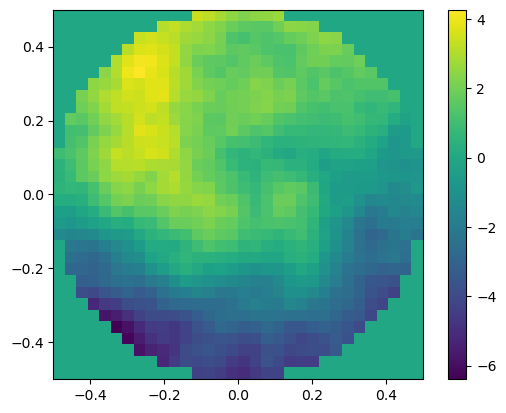

In [11]:
boston_actuator_grid = hcipy.make_pupil_grid(32,1)
aperture = hcipy.make_circular_aperture(1)(boston_actuator_grid)
outer_scale = 40 # meter
tau0 = 0.005 # seconds
boston_zernike_modes = hcipy.make_zernike_basis(num_modes, 
                                                1, boston_actuator_grid,
                                                2)
fried_parameter = 0.2
Cn_squared = Cn_squared_from_fried_parameter(fried_parameter, 500e-9)
velocity = 0.314 * fried_parameter / tau0
print(velocity)
layer = InfiniteAtmosphericLayer(boston_actuator_grid, Cn_squared, outer_scale, velocity)
corrected_layer=hcipy.atmosphere.ModalAdaptiveOpticsLayer(layer,boston_zernike_modes,1)
phase_screen_phase = layer.phase_for(633e-9) # in radian
#phase_screen_opd = phase_screen_phase * (633 / (2 * np.pi))
hcipy.imshow_field(phase_screen_phase*aperture)
plt.colorbar()
                      

<function matplotlib.pyplot.show(close=None, block=None)>

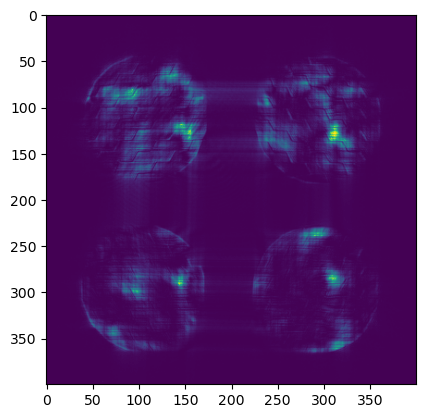

In [32]:

plt.imshow(image[0])
plt.show

In [34]:
image=list(wfs_frame)

In [35]:
image

[array([[7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        ...,
        [7., 7., 7., ..., 8., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.]], dtype=float32),
 array([[7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        ...,
        [7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.]], dtype=float32),
 array([[7., 7., 7., ..., 8., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        ...,
        [7., 7., 8., ..., 7., 7., 7.],
        [7., 7., 8., ..., 7., 7., 7.],
        [8., 7., 7., ..., 7., 7., 7.]], dtype=float32),
 array([[7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],
        ...,
        [7., 7., 7., ..., 7., 7., 7.],
        [7., 7., 7., ..., 7., 7., 7.],


In [44]:
curr_layer=corrected_layer
curr_layer.reset()
wfs_frames=[]
psf_frames=[]
wfs_directory="/home/lab/rnobileo/november5/wfs_images/"
psf_directory="/home/lab/rnobileo/november5/psf_images/"
for atmosphere_time in np.arange(0,150,0.1):    
    curr_layer.t= atmosphere_time
    phase_screen_phase = curr_layer.phase_for(633e-9) # in radian
    phase_screen_opd = phase_screen_phase * (633e-9 / (2 * np.pi)) * 1e9
    testbed.boston_dm.apply_shape("aberration",(phase_screen_opd).shaped)
    wfs_frame= testbed.pywfs_camera.take_raw_exposures(10)
    wfs_frame=list(wfs_frame)
    wfs_frame =np.median(wfs_frame,axis=0)
    wfs_frames.append(wfs_frame)
    
    fits.writeto(f"{wfs_directory}wfs_{atmosphere_time}.fits",wfs_frame,overwrite=True)
    psf_frame=testbed.vortex_camera.take_raw_exposures(10)
    psf_frame=list(psf_frame)
    psf_frame =np.median(psf_frame,axis=0)
    psf_frames.append(psf_frame)
    fits.writeto(f"{psf_directory}psf_{atmosphere_time}.fits",psf_frame,overwrite=True)
    sleep(0.1)
    #imshow_field(phase_screen_opd, vmin=-6, vmax=6, cmap='RdBu')

KeyboardInterrupt: 

In [40]:
import os
os.path.exists("/home/lab/rnobileo/november5/wfs_images")

False

In [ ]:
probe_amp= 10
slopes=[]
images=[]#np.zeros([2,400,400])
slope=0
N=10
for s in [1,-1]:
    testbed.boston_dm.apply_shape("aberration",(s*probe_amp*Z).shaped)

    image_ab = testbed.pywfs_camera.take_raw_exposures(N)
    print(type(image_ab))
    image_ab=np.array(list(image_ab))
    print(type(image_ab))
    print(image_ab.shape)
    image_ab=np.median(image_ab, axis=0)
    #image_ab /= np.sum(image_ab)
    images.append(image_ab)
    print(image_ab.shape)
    
    plt.title(f"sign = {s}")
    plt.imshow(image_ab)
    plt.show()
    
    #slope = s * (image_ab-image_ref)/(2*probe_amp)
    #slope = slope.ravel()
    #slope +=slope
slope = (images[0] - images[1]) / (2 * probe_amp)
slope=slope.ravel()
print(slope.shape)
print(type(images))
print(len(images))
print(images[0].shape)
print(images[1].shape)
print(slope.shape)
print(type(slope))
slopes = hcipy.ModeBasis([slope])
#images=np.array(images)  
#print(images.shape)
#image_slope = (images[1]-images[0])/(2*poke_amp)
#image_slope=image_slope.ravel()
#print(slopes.shape)

In [ ]:
rcond=1e-3
reconstruction_matrix = hcipy.inverse_tikhonov(slopes.transformation_matrix, rcond=rcond, svd =None)

In [ ]:
print(reconstruction_matrix)
print(reconstruction_matrix.shape)

In [ ]:
print("Expected +5:")
print(reconstruction_matrix @ (images[0] - image_ref).ravel())

print("Expected -5:")
print(reconstruction_matrix @ (images[1] - image_ref).ravel())

In [ ]:
test_amplitude =-75 #abberation strength 
testbed.boston_dm.apply_shape("aberration",(test_amplitude*Z).shaped)
N=10
image_ab = testbed.pywfs_camera.take_raw_exposures(N)
print(type(image_ab))
image_ab=np.array(list(image_ab))
print(type(image_ab))
print(image_ab.shape)
image_ab=np.median(image_ab, axis=0)
#image_ab /= np.sum(image_ab)

In [ ]:
image_dif=image_ab-image_ref
print(image_dif.shape)
print(image_dif.ravel().shape)
reconstruction_matrix@(image_dif.ravel())

In [ ]:
psf_directory="/home/lab/rnobileo/august4/psf/"
n=300
psf_ref = testbed.vortex_camera.take_raw_exposures(n)
psf_ref=np.array(list(psf_ref))
print(psf_ref.shape)
psf_ref=np.median(psf_ref,axis=0)
fits.writeto(f"{psf_directory}psf_{test_amplitude}.fits",psf_ref,overwrite=True)
print(psf_ref.shape)
plt.imshow(psf_ref)

In [ ]:
wfs_directory="/home/lab/rnobileo/august4/wfs/"
n=300
wfs_ref = testbed.pywfs_camera.take_raw_exposures(n)
wfs_ref=np.array(list(wfs_ref))
wfs_ref=np.median(wfs_ref,axis=0)
fits.writeto(f"{wfs_directory}wfs_{test_amplitude}.fits",wfs_ref,overwrite=True)
plt.imshow(wfs_ref)

In [ ]:
psf_directory="/home/lab/rnobileo/august4/darks/" #laser off
n=300
psf_ref = testbed.pywfs_camera.take_raw_exposures(n)
psf_ref=np.array(list(psf_ref))
psf_ref=np.median(psf_ref,axis=0)
fits.writeto(f"{psf_directory}dark_wfs.fits",psf_ref,overwrite=True)
plt.imshow(psf_ref)

In [ ]:
wfs_ref = testbed.pywfs_camera.take_raw_exposures(3)
wfs_ref=list(wfs_ref)
wfs_ref[0]


In [ ]:
wfs_ref

In [ ]:
plt.imshow(wfs_ref[0])

In [ ]:
wfs_directory="/home/lab/rnobileo/july23/wfs/"
wfs_ref = testbed.pywfs_camera.take_raw_exposures(3)
wfs_ref=list(wfs_ref)
fits.writeto(f"{wfs_directory}wfs_test.fits",wfs_ref,overwrite=True)

In [ ]:
wfs=fits.getdata("/home/lab/rnobileo/july23/wfs/wfs_10.fits")
plt.imshow(wfs)

In [ ]:
from time import sleep

In [ ]:
sleep(2)

In [ ]:
for i in range(2,30):
    Z = hcipy.mode_basis.zernike_ansi(i,D=1,grid=actuator_grid)
    amplitude =-60.0 #abberation strength 
    testbed.boston_dm.apply_shape("aberration",(amplitude*Z).shaped)
    sleep(2)

In [ ]:
hcipy.imshow_field(Z)